# COMP7015 Group Project – Topic 1: Plant Disease Classification

We classify tomato leaf images from the [PlantVillage dataset](https://github.com/spMohanty/PlantVillage-Dataset) into **healthy, early blight, leaf mold and spider mites** (two-spotted spider mite damage). We compare a custom CNN with attention, a fine-tuned ResNet18 and a fine-tuned Vision Transformer. Then we ask how robust they are: to the photo background, to colour, lighting and image quality, and to photos taken outside the lab. Every class comes from its own photo series with its own background. A classifier that sees only the border of a PlantVillage photo already predicts the class far above chance (Noyan, 2022), so the background is a likely shortcut.

| Rubric criterion (Excellent) | What the notebooks do | Notebook / Section |
|---|---|---|
| Reproducible leaf-group splits, no leakage | One training series per class with official leaf ids only; split by leaf id with a fixed seed; audit that no leaf id crosses splits | 01 / 3, 5 |
| Efficient caching / IO | Images are decoded and resized **once** and cached as a uint8 tensor | 01 / 4 |
| Justified class balance | Class-weighted loss for the CNNs, tested in an ablation | 01 / 6, 02 / 9 |
| Sound fine-tuning (freeze/unfreeze, schedulers) | Two-stage fine-tuning (train head → unfreeze), AdamW, learning-rate schedules, gradient clipping, checkpoints; three ViT fine-tuning strategies (head only, last two blocks, full) | 02 / 8–9, 03 / 10 |
| Attention / transformer modelling | Custom CNN with **Squeeze-and-Excitation channel attention** and a pre-trained **Vision Transformer (ViT-B/16)** | 02 / 7, 03 / 10 |
| Systematic tuning and ablations | Learning-rate sweep and ablations of attention, augmentation, dropout, class weighting, scheduler and batch size; ResNet18 and ViT fine-tuning strategies; ViT augmentation ablation | 02 / 9, 03 / 10 |
| Per-class metrics, macro-F1, confusion matrix, error analysis | Mean ± standard deviation over 3 training seeds, per-class F1, confusion matrices, errors that every seed makes, misclassified images, Grad-CAM | 04 / 11, 13 |
| Compute trade-offs | Parameters, model size, inference latency; trainable parameters, training time and peak memory | 03 / 10, 04 / 12 |
| Background bias / robustness | Same test leaves with background removed, grayscale, darker, blurred and noisy; ViT retrained on grayscale and background-removed photos; the same leaf on a background of its own and of another class; Grad-CAM weight on the leaf | 05 / 14–17 |
| Countermeasure for the background shortcut | Training with random backgrounds, with a class-matched control | 05 / 18 |
| Beyond controlled photos | A healthy photo series left out of training and PlantDoc field photos | 05 / 19 |
| Deterministic, config-driven | One `CFG` dictionary, saved with every run; fixed seeds; deterministic algorithms; runs on CUDA, Apple MPS and CPU | 01 / 1 |

**Notebooks.** The project is split into six notebooks that run in order: `01_data` → `02_cnn_resnet` → `03_vit` → `04_test_evaluation` → `05_robustness` → `06_discussion`. The shared code (data protocol, models, training engine, evaluation tools) lives in the `plantdisease/` package; the notebooks show the steps and the results.

**Uncertainty.** All models are trained with three seeds (42, 43, 44) on one fixed split. Results are reported as the mean ± sample standard deviation over the seeds. Two models trained with the same seeds are compared seed by seed ("higher in k of 3 seeds"). The standard deviation reflects the randomness of training; it does not cover a different choice of test leaves.

**Runtime.** Every training run is saved under `OUT_DIR/runs/`. Re-running a notebook loads finished runs instead of retraining them, so an interrupted run can simply be resumed. A GPU (CUDA or Apple MPS) is recommended; notebook 04 reports the training time of every model.

## 1. Setup & Configuration

All settings live in one `CFG` dictionary (`plantdisease/config.py`). Paths, epochs and seeds can also be overridden with environment variables without editing the code, e.g. `EPOCHS_CNN=1 SEEDS=42` for a quick test. The configuration is saved to `OUT_DIR/config.json`. The notebooks need Python 3.10 or newer, PyTorch 2.0 or newer and torchvision 0.15 or newer (`transforms.v2`). They pick the device automatically: CUDA, then Apple MPS, then CPU.

In [1]:
import os
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from torchvision.utils import make_grid

from plantdisease.config import CFG, CLASSES, SHORT_NAMES, USE_AMP, device, out_path
from plantdisease.data import (
    DATA_ROOT,
    CachedDataset,
    border_brightness,
    build_cache,
    chunked,
    class_weights,
    data_fingerprint,
    download_plantvillage,
    load_records,
    make_loader,
    make_split,
    train_tf,
)
from plantdisease.plots import finish

In [2]:
CFG  # saved to OUT_DIR/config.json

{'data_root': './PlantVillage-Dataset',
 'cache_dir': './cache',
 'out_dir': './outputs',
 'classes': ['Tomato___healthy',
  'Tomato___Early_blight',
  'Tomato___Leaf_Mold',
  'Tomato___Spider_mites Two-spotted_spider_mite'],
 'train_series': {'Tomato___healthy': 'rs_hl',
  'Tomato___Early_blight': 'rs_erly.b',
  'Tomato___Leaf_Mold': 'crnl_l.mold',
  'Tomato___Spider_mites Two-spotted_spider_mite': 'com.g_spm_fl'},
 'field_root': './PlantDoc-Dataset',
 'field_photos': {'url': 'https://github.com/pratikkayal/PlantDoc-Dataset',
  'folders': {'Tomato___healthy': 'Tomato leaf',
   'Tomato___Early_blight': 'Tomato Early blight leaf',
   'Tomato___Leaf_Mold': 'Tomato mold leaf',
   'Tomato___Spider_mites Two-spotted_spider_mite': 'Tomato two spotted spider mites leaf'}},
 'min_series_photos': 20,
 'img_size': 224,
 'split_seed': 42,
 'split_fractions': (0.7, 0.15),
 'seeds': [42, 43, 44],
 'epochs': {'cnn': 50, 'resnet18': 16, 'vit_b_16': 15},
 'countermeasure': {'swap_prob': 0.5},
 'num_wo

In [3]:
print("Device in use:", device, "| mixed precision:", USE_AMP)
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

Device in use: mps | mixed precision: False
torch 2.15.0 | torchvision 0.29.2


## 2. Download the Data

We use a sparse git checkout with only the four tomato folders of `raw/color` (the RGB images used for training) and the root files (incl. `leaf-map.json`). We also fetch `raw/segmented`, the same photos with the background removed. They are used in notebook 05 to test background bias, to train on background-removed photos and to cut the leaf out of the photo.

In [4]:
folders = download_plantvillage()  # sparse git checkout, skipped if the folders exist
for f in folders:
    print(f"{f:60s} {len(os.listdir(os.path.join(DATA_ROOT, f)))} images")

raw/color/Tomato___healthy                                   1591 images
raw/color/Tomato___Early_blight                              1000 images
raw/color/Tomato___Leaf_Mold                                 952 images
raw/color/Tomato___Spider_mites Two-spotted_spider_mite      1676 images
raw/segmented/Tomato___healthy                               1591 images
raw/segmented/Tomato___Early_blight                          1000 images
raw/segmented/Tomato___Leaf_Mold                             952 images
raw/segmented/Tomato___Spider_mites Two-spotted_spider_mite  1676 images


## 3. Leaf Grouping & Label Verification

Every image must be assigned to a **physical leaf**, so that all photos of one leaf end up in the same split.

1. **Official metadata.** The image identifier from the file name is looked up in `leaf-map.json`, keeping only an entry of the image's own class. Most leaves are photographed four times.
2. **One training series per class.** A class can consist of several photo series (the series is the first part of the file name, for example `RS_HL` or `GH_HL`) with their own background, light and camera. We train on **one series per class that has official leaf ids** (`CFG["train_series"]`): `RS_HL` (healthy), `RS_Erly.B` (early blight), `Crnl_L.Mold` (leaf mold) and `Com.G_SpM_FL` (spider mites). Early blight, leaf mold and spider mites have only this one series.
3. **Series test.** The healthy greenhouse series `GH_HL` has no official leaf ids. It is left out of training, validation and the clean test and is used in notebook 05 (Section 19.1) as photos of the same class from a different series.
4. **Exclusion.** Photos of a training series without any leaf information are excluded.

In [5]:
# leaf ids from leaf-map.json, training series vs. left-out series (plantdisease/data.py: load_records)
leaf_map, all_df, df, other_df = load_records()

all_df.groupby(["class_name", "series"]).agg(
    photos=("path", "size"),
    official_ids=("source", lambda s: int((s == "leaf map").sum())),
    role=("training_series", lambda s: "training" if s.all() else "not trained on"),
).loc[CLASSES]

photos  \
class_name                                    series                            
Tomato___healthy                              2700323949_95aa2eaa01_o       1   
                                              cg1                           1   
                                              gh_hl                       590   
                                              rs_hl                       999   
Tomato___Early_blight                         rs_erly.b                  1000   
Tomato___Leaf_Mold                            crnl_l.mold                 952   
Tomato___Spider_mites Two-spotted_spider_mite com.g_spm_fl               1676   

                                                                       official_ids  \
class_name                                    series                                  
Tomato___healthy                              2700323949_95aa2eaa01_o             0   
                                              cg1                                 0   
                                              gh_hl                               0   
                                              rs_hl                             999   
Tomato___Early_blight                         rs_erly.b                         999   
Tomato___Leaf_Mold                            crnl_l.mold                       952   
Tomato___Spider_mites Two-spotted_spider_mite com.g_spm_fl                     1676   

                                                                                 role  
class_name                                    series                                   
Tomato___healthy                              2700323949_95aa2eaa01_o  not trained on  
                                              cg1                      not trained on  
                                              gh_hl                    not trained on  
                                              rs_hl                          training  
Tomato___Early_blight                         rs_erly.b                      training  
Tomato___Leaf_Mold                            crnl_l.mold                    training  
Tomato___Spider_mites Two-spotted_spider_mite com.g_spm_fl                   training

In [6]:
# Label check (all photos, before any filtering): the class stored in the leaf map must agree with the folder label
map_classes = all_df["key"].map(
    lambda k: {e.split(":::")[0] for e in leaf_map.get(k, [])}
)
conflicts = sum(
    len(m) > 0 and c not in m
    for c, m in zip(all_df["class_name"], map_classes, strict=True)
)
print("Images whose leaf-map class disagrees with the folder label:", conflicts)

# Image check: every file must open; record (size, mode)
image_info = Counter()
for p in df["path"]:
    with Image.open(p) as img:
        image_info[(img.size, img.mode)] += 1
print("Image (size, mode) counts:", dict(image_info))

Images whose leaf-map class disagrees with the folder label: 0
Image (size, mode) counts: {((256, 256), 'RGB'): 4626}


## 4. Image Cache & Background Analysis

**Caching.** Decoding JPEGs and resizing them in every epoch is wasted work. Each image is decoded, converted to RGB and resized to 224×224 **once**, then stored as one `uint8` tensor in `cache/`. Training then only applies cheap tensor operations. The cache is rebuilt automatically if the image list or size changes.

**Background.** We measure the brightness of a 12-pixel border around every image, to see whether the photo background differs between classes. Every class comes from its own photo series, so it may, and a model could learn the background instead of the disease.

In [7]:
t0 = time.time()
# decoded + resized once, uint8 (N, 3, 224, 224)
IMAGES = build_cache(df["path"], "color")
LABELS = torch.tensor(df["label"].values)
print(
    f"Cached images: {tuple(IMAGES.shape)}, {IMAGES.numel() / 1e9:.2f} GB, {time.time() - t0:.1f}s"
)

Cached images: (4626, 3, 224, 224), 0.70 GB, 3.8s


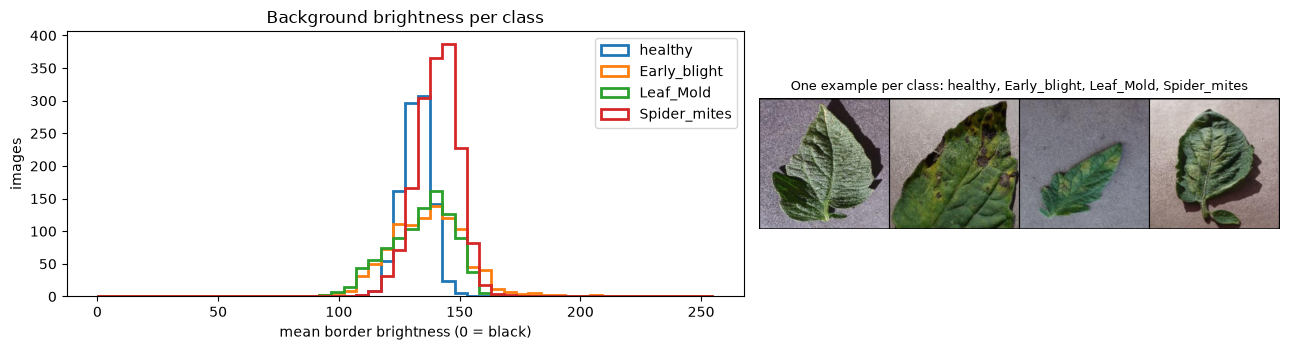

,mean,std,min,max
class_name,,,,
Tomato___healthy,132.0,6.0,108.0,152.0
Tomato___Early_blight,137.0,16.0,92.0,216.0
Tomato___Leaf_Mold,134.0,13.0,83.0,175.0
Tomato___Spider_mites Two-spotted_spider_mite,141.0,9.0,65.0,192.0


In [8]:
# Background brightness: mean gray level of a 12-pixel border around each image
df["border_brightness"] = chunked(border_brightness, IMAGES).numpy()

fig, axes = plt.subplots(
    1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.3, 1]}
)
for c, name in enumerate(SHORT_NAMES):
    axes[0].hist(
        df.loc[df.label == c, "border_brightness"],
        bins=50,
        range=(0, 255),
        histtype="step",
        linewidth=2,
        label=name,
    )
axes[0].set_xlabel("mean border brightness (0 = black)")
axes[0].set_ylabel("images")
axes[0].set_title("Background brightness per class")
axes[0].legend()
examples = [df.index[df.label == c][0] for c in range(len(CLASSES))]
grid = make_grid(IMAGES[examples], nrow=len(CLASSES), padding=2)
axes[1].imshow(grid.permute(1, 2, 0))
axes[1].set_title("One example per class: " + ", ".join(SHORT_NAMES), fontsize=9)
axes[1].axis("off")
finish("background_brightness.png")

df.groupby("class_name")["border_brightness"].agg(
    ["mean", "std", "min", "max"]
).reindex(CLASSES).round(0)

## 5. Leaf-Group Split & Leakage Audit

Within each class, the official leaf ids are shuffled with a fixed seed and split 70 / 15 / 15 into train / validation / test. All photos of one leaf follow its leaf id. The split seed is separate from the training seeds, so all models and seeds share **exactly the same split**. The audit asserts that no official leaf id appears in two splits.

In [9]:
# 70/15/15 split of the official leaf ids of every class; the audit is asserted inside make_split
train_idx, val_idx, test_idx = make_split(df)
print(
    f"Split seed: {CFG['split_seed']} | every official leaf id lies in exactly one split"
)
# fingerprint of the training photos, the series and the split seed: a saved run is only reused for the same data
DATA_ID = data_fingerprint(df, train_idx)

df[["path", "class_name", "leaf_id", "split"]].to_csv(
    out_path("split.csv"), index=False
)
counts = pd.crosstab(df["class_name"], df["split"], margins=True).reindex(
    [*CLASSES, "All"]
)[["train", "val", "test", "All"]]
counts["leaf ids"] = [
    *df.groupby("class_name")["leaf_id"].nunique().reindex(CLASSES).tolist(),
    df.leaf_id.nunique(),
]
counts.to_csv(out_path("class_counts.csv"))
counts

Split seed: 42 | every official leaf id lies in exactly one split


split,train,val,test,All,leaf ids
class_name,,,,,
Tomato___healthy,699,152,148,999,250
Tomato___Early_blight,699,152,148,999,250
Tomato___Leaf_Mold,668,144,140,952,238
Tomato___Spider_mites Two-spotted_spider_mite,1172,252,252,1676,419
All,3238,700,688,4626,1157


### 5.1 How much does the background alone tell?

Noyan (2022) reported that a classifier that sees only eight pixels from the border of a PlantVillage photo predicts the class far above chance (49% on 38 classes). Every class here comes from its own photo series, so the background may already reveal the class. A random forest sees **only the mean colour of the four image corners** (12 numbers per photo, no leaf). It is trained on the training photos and evaluated on the validation photos (the test photos stay untouched). Two reference points tell what the score means: guessing uniformly (25%) and always answering with the largest class. A score far above both means that the background alone predicts the class.

In [10]:
def corner_features(images, size=24):
    # Mean colour of the four image corners: the background only, 12 numbers per photo.
    corners = [
        images[:, :, :size, :size],
        images[:, :, :size, -size:],
        images[:, :, -size:, :size],
        images[:, :, -size:, -size:],
    ]
    return torch.cat([c.float().mean(dim=(2, 3)) for c in corners], dim=1).numpy()


X_corners, y_all = corner_features(IMAGES), LABELS.numpy()
corner_model = RandomForestClassifier(
    n_estimators=200, random_state=CFG["split_seed"], n_jobs=-1
).fit(X_corners[train_idx], y_all[train_idx])
corner_pred = corner_model.predict(X_corners[val_idx])
majority_pred = np.full(len(val_idx), np.bincount(y_all[train_idx]).argmax())
background_only = pd.DataFrame(
    {
        "accuracy": [
            accuracy_score(y_all[val_idx], corner_pred),
            accuracy_score(y_all[val_idx], majority_pred),
        ],
        "macro-F1": [
            f1_score(y_all[val_idx], corner_pred, average="macro"),
            f1_score(y_all[val_idx], majority_pred, average="macro"),
        ],
    },
    index=["four image corners only", "always the largest class (reference)"],
)
background_only.to_csv(out_path("background_only.csv"))
background_only.round(3)

,accuracy,macro-F1
four image corners only,0.873,0.864
always the largest class (reference),0.360,0.132


## 6. Preprocessing, Augmentation & Class Weights

The cached images are already resized to 224×224 (the whole photo, no crop). Every split is converted to float in [0, 1] and normalised with the ImageNet mean/std. The same preprocessing is used for all models, including the ViT.

**Training-only augmentation** must not change the symptoms:
- horizontal/vertical flips and **rotations by multiples of 90°**, because a leaf has no fixed orientation. These rotations are lossless and add no black corners, which matters because the background could carry class information (Section 4).
- a mild brightness/contrast jitter (±10%) for lighting changes. There is no hue/saturation change, so lesion colours (yellow halos, brown spots, mould) are preserved.

**Class balance.** Spider mites have about 1.7× more training images than the other classes. Rather than throwing data away, the CNNs use a **class-weighted cross-entropy loss** with weight $w_c = N / (K \cdot n_c)$, so errors on smaller classes cost more. Section 9 tests whether this helps. The ViT follows Zhouyang's protocol without class weights (notebook 03).

The transforms, the cached dataset and the loaders are defined in `plantdisease/data.py`.

Class weights: {'healthy': 1.1579999923706055, 'Early_blight': 1.1579999923706055, 'Leaf_Mold': 1.2120000123977661, 'Spider_mites': 0.6909999847412109}


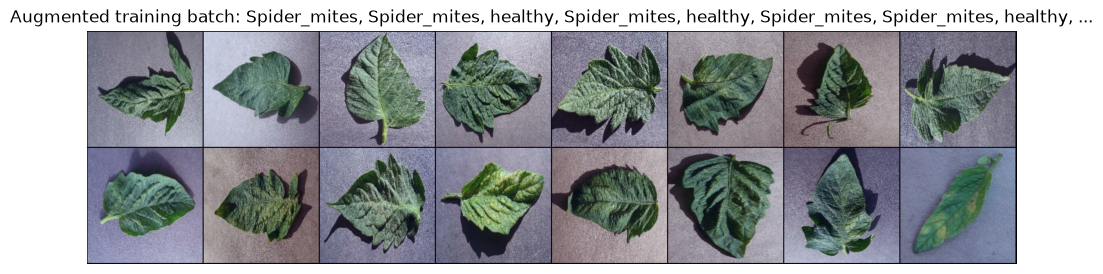

In [11]:
CLASS_WEIGHTS = class_weights(df, train_idx)  # w_c = N / (K * n_c)
print(
    "Class weights:",
    dict(zip(SHORT_NAMES, CLASS_WEIGHTS.numpy().round(3).tolist(), strict=True)),
)

# Visualise augmented training images
dataset = CachedDataset(IMAGES, LABELS, train_idx, train_tf)
x, y = next(iter(make_loader(dataset, 16, seed=0)))
plt.figure(figsize=(12, 3.5))
plt.imshow(make_grid(x, nrow=8, padding=2, normalize=True).permute(1, 2, 0))
plt.axis("off")
plt.title(
    "Augmented training batch: " + ", ".join(SHORT_NAMES[c] for c in y[:8]) + ", ..."
)
plt.show()

**Hand-over.** The following notebooks rebuild exactly this data protocol with `plantdisease.data.prepare()`, which runs the same steps (records, cache, split) from the image cache in a few seconds. The split is saved to `OUT_DIR/split.csv`.